In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
# df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [5]:
print("- PART A -")
print("----------------")
print("Before cleaning:")
print("shape:", df.shape)
print("missing per column:\n", df.isna().sum())
print("max study_hours:", df['study_hours'].max())
print("min attendance:", df['attendance'].min())
 
clean = df.copy()
clean.loc[clean['study_hours'] > 24, 'study_hours'] = np.nan  
clean.loc[clean['attendance'] < 0, 'attendance'] = np.nan      
clean = clean.dropna().reset_index(drop=True)  

print("----------------")
 
print("\nAfter cleaning shape:", clean.shape)
X = clean[['study_hours', 'attendance', 'previous_mark']]
y = clean['final_score']
print("feature matrix X shape:", X.shape, "| target y shape:", y.shape)


print("-----------------")


print("- We found 6 missing study_hour values from row 0-5 and 1 outlier which is 50 hours on row 99 plus 1 impossible which is a negative number(10). ")
print("- Removing is better because studying 50 hours is not possible considering there's only 24 hours in a day so it's not even a real extreme same view on the -10 attendance.")
print("- Numerical columns are all four.")
print("- Target column is final_score because it's the one that depends on the others and it's what we want to predict.")

- PART A -
----------------
Before cleaning:
shape: (100, 4)
missing per column:
 study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64
max study_hours: 50.0
min attendance: -10.0
----------------

After cleaning shape: (92, 4)
feature matrix X shape: (92, 3) | target y shape: (92,)
-----------------
- We found 6 missing study_hour values from row 0-5 and 1 outlier which is 50 hours on row 99 plus 1 impossible which is a negative number(10). 
- Removing is better because studying 50 hours is not possible considering there's only 24 hours in a day so it's not even a real extreme same view on the -10 attendance.
- Numerical columns are all four.
- Target column is final_score because it's the one that depends on the others and it's what we want to predict.


In [11]:
print("- PART B -")
print("------------------------------------")

summary = pd.DataFrame({
    'mean': clean.mean(),
    'median': clean.median(),
    'std': clean.std()
})
print(summary.round(2))

print("------------------------------------")
print("- For every column the mean and median are close with eachother meaning it's fairly symmetric")
print("- The biggest std is previous_mark whcih mean students previous mark vary more than their studying hours.")
print("- The average student studies for 4.7 hours and attends around 86% of classes showing that students are commited.")


- PART B -
------------------------------------
                mean  median    std
study_hours     4.73    4.70   1.85
attendance     85.66   86.74   9.68
previous_mark  70.70   71.01  16.50
final_score    42.72   42.76   6.20
------------------------------------
- For every column the mean and median are close with eachother meaning it's fairly symmetric
- The biggest std is previous_mark whcih mean students previous mark vary more than their studying hours.
- The average student studies for 4.7 hours and attends around 86% of classes showing that students are commited.


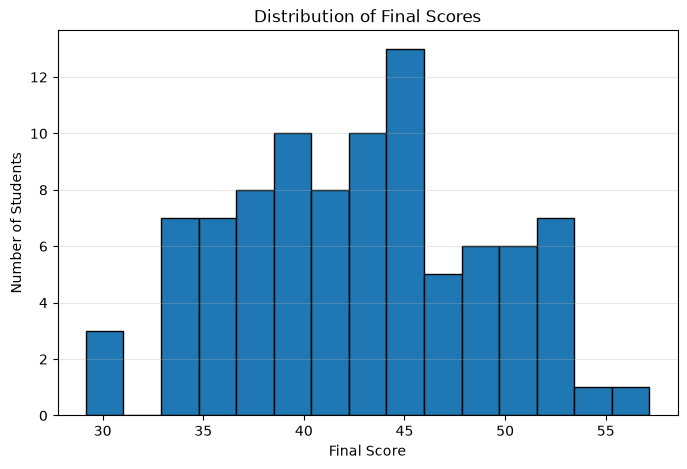

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    clean['final_score'],
    bins=15,
    edgecolor='black'
)

plt.title('Distribution of Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Number of Students')

plt.grid(axis='y', alpha=0.3)
plt.show()




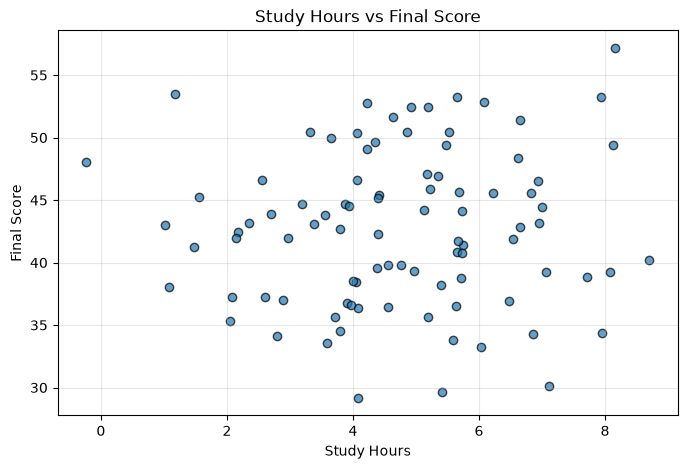

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    clean['study_hours'],
    clean['final_score'],
    alpha=0.7,
    edgecolor='black'
)

plt.title('Study Hours vs Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')

plt.grid(alpha=0.3)
plt.show()

In [22]:
print("-The scatter plot shows a shapless cloud this shows that study_score doesn't vsibly mean higher score in this data.")

-The scatter plot shows a shapless cloud this shows that study_score doesn't vsibly mean higher score in this data.


In [33]:
print("- PART D -")

print("------------------------------------")


r = clean['study_hours'].corr(clean['final_score'])
print("Pearson r (study_hours, final_score):", round(r, 3))
print("r for attendance:", round(clean['attendance'].corr(clean['final_score']), 3))
print("r for previous_mark:", round(clean['previous_mark'].corr(clean['final_score']), 3))
print("r(study_hours, previous_mark):", round(clean['study_hours'].corr(clean['previous_mark']),3))

print("------------------------------------")

print("-It does not guarentee a specific score.")
print("-It could be previous mark, the link isn't purely because of study time or it could be attendance as well.")

- PART D -
------------------------------------
Pearson r (study_hours, final_score): 0.051
r for attendance: 0.435
r for previous_mark: 0.543
r(study_hours, previous_mark): 0.169
------------------------------------
-It does not guarentee a specific score.
-It could be previous mark, the link isn't purely because of study time or it could be attendance as well.


In [28]:
print("- PART E -")

print("------------------------------------")


x = X.iloc[0].values           
w = np.array([0.5, 0.2, 0.4])
b = 5
y_hat = np.dot(w, x) + b
print("x =", x.round(2))
print("y_hat = w . x + b =", round(y_hat, 2))
print("actual final_score =", round(y.iloc[0], 2))

print("------------------------------------")
print("- The weight(w) shows how much the features matter so if the w is bigger the score is also higher.")
print("- b is the intercept without it the line would go through the origin so the model could not fit up or down to fit the data.")
    

- PART E -
------------------------------------
x = [  8.16 103.86  77.73]
y_hat = w . x + b = 60.94
actual final_score = 57.17
------------------------------------
- The weight(w) shows how much the features matter so if the w is bigger the score is also higher.
- b is the intercept without it the line would go through the origin so the model could not fit up or down to fit the data.


In [34]:
print("- PART F -")

print("------------------------------------")



for col in ['study_hours', 'previous_mark']:
    print(col, "range:", round(clean[col].min(), 1), "to", round(clean[col].max(), 1),
          "| spread:", round(clean[col].max() - clean[col].min(), 1))
    clean[col + '_scaled'] = (clean[col] - clean[col].mean()) / clean[col].std()
print(clean[['study_hours_scaled', 'previous_mark_scaled']].agg(['mean', 'std']).round(3))



print("------------------------------------")

print("- Since KNN uses distance. It's values only go from 0-9, while previous_mark goes from around 21-128.")
print("- So it would mostly ignore study_hours. so if there is a big difference in previous_mark the the distance will be huge")
print("- There should be scaling so that both are put on the same level.")

- PART F -
------------------------------------
study_hours range: -0.2 to 8.7 | spread: 8.9
previous_mark range: 21.4 to 127.8 | spread: 106.4
      study_hours_scaled  previous_mark_scaled
mean                -0.0                   0.0
std                  1.0                   1.0
------------------------------------
- Since KNN uses distance. It's values only go from 0-9, while previous_mark goes from around 21-128.
- So it would mostly ignore study_hours. so if there is a big difference in previous_mark the the distance will be huge
- There should be scaling so that both are put on the same level.
